## Open RayCloudTools data 

Work with QSMs from **RayCloudTools/RayExtract** (files) to extract tree-level metrics. #15Oct2026

**Ankasa plot** (50 x 40 m2)  Ghana

Actual plot location is missing

No L2A (FH) data available --- being processed by the ESA Team 

# Tree file. Optional per-tree attributes (e.g. 'height, crown_radius, ') followed by 'x,y,z,radius' and any additional per-segment attributes:
# x,y,z,radius,parent_id,section_id
533919.4054,582308.7427,123.5200,0.0540,-1,0, 
533919.4160,582308.7657,124.2056,0.0540,0,2225, 
533919.4044,582308.7294,124.4730,0.0540,1,4450, 
533919.4156,582308.7205,124.7852,0.0540,2,6916, 
533919.4304,582308.7174,125.0167,0.0540,3,9473, 
533919.4477,582308.7157,125.2863,0.0540,4,12239, 
533919.4716,582308.7066,125.5426,0.0540,5,15178, ... 533919.4600,582307.7500,128.5312,0.0168,45,138742 # last segment

In [1]:
# Open a RayCloudTools output - Tree-level metrics at plot (QSMs)
file_path = '/home/jovyan/Examples_and_Data/Workshops/BIOMASS-Coding2026/TLS/Ankasa/c01_r02_subsampled_1cm_trees.txt'

In [2]:
## Dataframe ::: DBH , Ht , Tree Volume ,
import numpy as np
import pandas as pd

# List to hold the row data
data_records = []

# Open the text file and skip the first 2 rows
with open(file_path, "r") as file:
    lines = file.readlines()[2:]

# Loop through every single row in the file
for line_num, line in enumerate(lines, start=3):
    if not line.strip():
        continue

    # Split the row by commas and convert to numbers
    tokens = [float(x) for x in line.strip().split(",") if x.strip()]

    # Reset variables specifically for THIS row/tree
    row_volume = 0.0
    prev_x, prev_y, prev_z = None, None, None
    
    # Trackers for height and DBH
    first_z = None
    last_z = None
    dbh_qsm = None  # Will hold the diameter once found

    # Step through the current row 6 values at a time
    for i in range(0, len(tokens), 6):
        chunk = tokens[i : i + 6]
        if len(chunk) < 6:
            continue
        x, y, z, radius, parent_id, section_id = chunk

        # Track Z values for height calculation
        if first_z is None:
            first_z = z  # Ground level reference
        last_z = z

        # Extract DBH: Find the first cylinder at or above 1.25m from ground
        if dbh_qsm is None and (z - first_z) >= 1.25:
            dbh_qsm = radius * 2

        # If it's the root node, establish the starting position
        if parent_id == -1:
            prev_x, prev_y, prev_z = x, y, z
            continue

        # Calculate the cylinder segment if we have a starting point
        if prev_x is not None:
            length = np.sqrt(
                (x - prev_x) ** 2 + (y - prev_y) ** 2 + (z - prev_z) ** 2
            )
            cylinder_volume = np.pi * (radius**2) * length
            row_volume += cylinder_volume

            # Move the starting point forward to the current node
            prev_x, prev_y, prev_z = x, y, z

    # Calculate tree height
    tree_height = (last_z - first_z) if first_z is not None else 0.0
    
    # Fallback if a tree is shorter than 1.25m and no DBH cylinder was reached
    if dbh_qsm is None:
        dbh_qsm = 0.0 #Implemented

    # Append all metadata to your records list
    data_records.append({
        "RowNumber": line_num, 
        "TotalVolume": row_volume,
        "TreeHeight": tree_height,
        "DBHqsm": dbh_qsm
    })

In [3]:
# Create the final DataFrame
df = pd.DataFrame(data_records)

# Display the updated DataFrame
print("\nGenerated DataFrame with DBHqsm:")
print(df)


Generated DataFrame with DBHqsm:
      RowNumber  TotalVolume  TreeHeight  DBHqsm
0             3     0.061147      5.0112  0.1080
1             4     0.021821      3.3694  0.0898
2             5     0.023828      3.5400  0.0916
3             6     0.015917      3.3827  0.0874
4             7     0.125313      4.3086  0.1172
...         ...          ...         ...     ...
2220       2223     0.003122      1.6525  0.0278
2221       2224     0.010995      2.6082  0.0684
2222       2225     0.000639      0.7667  0.0000
2223       2226     0.037512      1.7201  0.0674
2224       2227     0.010962      2.0520  0.0534

[2225 rows x 4 columns]


In [4]:
## Dataframe properties

# 1. Check the dimensions
print(f"DataFrame Shape: {df.shape}")
print(f"Total Rows: {df.shape[0]}")
print(f"Maximum values found in a single row: {df.shape[1]}\n")

# 2. View the distribution of elements per row
# This tells you how long each individual row originally was
values_per_row = df.notna().sum(axis=1)
print("--- Distribution of Values per Row ---")
print(values_per_row.describe())

# 3. Print the technical overview
print("\n--- DataFrame Structural Info ---")
df.info()

# 4. Preview the actual data matrix
print("\n--- First 5 Rows Preview ---")
print(df.head())


DataFrame Shape: (2225, 4)
Total Rows: 2225
Maximum values found in a single row: 4

--- Distribution of Values per Row ---
count    2225.0
mean        4.0
std         0.0
min         4.0
25%         4.0
50%         4.0
75%         4.0
max         4.0
dtype: float64

--- DataFrame Structural Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   RowNumber    2225 non-null   int64  
 1   TotalVolume  2225 non-null   float64
 2   TreeHeight   2225 non-null   float64
 3   DBHqsm       2225 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 69.7 KB

--- First 5 Rows Preview ---
   RowNumber  TotalVolume  TreeHeight  DBHqsm
0          3     0.061147      5.0112  0.1080
1          4     0.021821      3.3694  0.0898
2          5     0.023828      3.5400  0.0916
3          6     0.015917      3.3827  0.0874
4          7     0.125313    

In [5]:
# Convert DBHqsm from meters to centimeters
df["DBHqsm"] = df["DBHqsm"] * 100

# Optional: Rename the column to reflect the new units
df.rename(columns={"DBHqsm": "DBHqsm_cm"}, inplace=True)

# Generate summary statistics for just Volume and Height
summary_stats = df[["TotalVolume", "TreeHeight", "DBHqsm_cm"]].describe()

# Display the summary table
print("\n=== Summary Statistics ===")
print(summary_stats.round(4))  # .round(4) keeps the output clean


=== Summary Statistics ===
       TotalVolume  TreeHeight  DBHqsm_cm
count    2225.0000   2225.0000  2225.0000
mean        1.1984      4.2189     8.7206
std         9.2957      4.2895     7.3381
min         0.0002      0.2100     0.0000
25%         0.0067      1.9515     4.9600
50%         0.0220      2.8700     7.5200
75%         0.0950      4.5276    10.4800
max       205.6533     37.8300   138.0200


In [7]:
# Calculate the grand total volume
grand_total_volume = df["TotalVolume"].sum()

total_agbiomass = df["TotalVolume"].sum() * 0.5 # Wood density - Biomass convertion
 
print(f"\nGrand Total Volume for All Rows: {grand_total_volume:.4f} m3")

print(f"\nBiomass in plot: {total_agbiomass:.4f} Kg")


Grand Total Volume for All Rows: 2666.4612 m3

Biomass in plot: 1333.2306 Kg


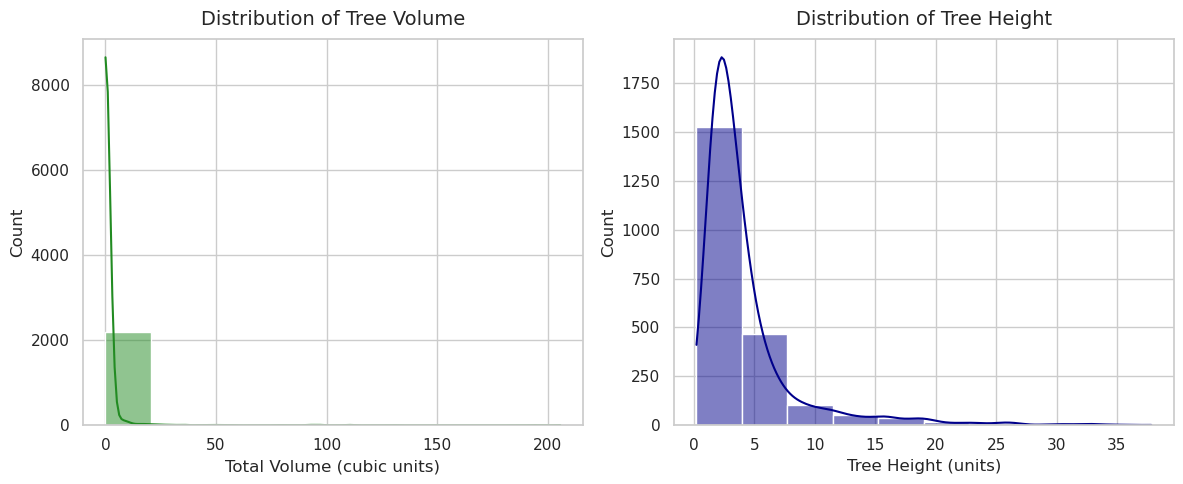

In [8]:
# Visualize Ht and Volume distribution
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style
sns.set_theme(style="whitegrid")

# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Distribution Plot for Total Volume
sns.histplot(
    data=df,
    x="TotalVolume",
    kde=True,
    color="forestgreen",
    ax=axes[0],
    bins=10,
)
axes[0].set_title("Distribution of Tree Volume", fontsize=14, pad=10)
axes[0].set_xlabel("Total Volume (cubic units)", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)

# 2. Distribution Plot for Tree Height
sns.histplot(
    data=df, 
    x="TreeHeight", 
    kde=True, 
    color="darkblue", 
    ax=axes[1], 
    bins=10
)
axes[1].set_title("Distribution of Tree Height", fontsize=14, pad=10)
axes[1].set_xlabel("Tree Height (units)", fontsize=12)
axes[1].set_ylabel("Count", fontsize=12)

# Optimize layout and display the plots
plt.tight_layout()
plt.show()


In [13]:
# Subset DataFrame - TreeVolume Range (10-300)
df_subset = df[df["TotalVolume"].between(12, 4000)].copy()

# View the new filtered DataFrame
print(f"Subset created with {len(df_subset)} rows.")
print(df_subset)

Subset created with 38 rows.
      RowNumber  TotalVolume  TreeHeight  DBHqsm_cm
6             9    26.667942     25.3125      33.74
61           64    16.570234     18.7900      11.18
92           95    45.221295     32.3100      28.30
123         126    91.147252     23.4550      43.22
140         143    93.249082     33.2850      69.56
152         155    96.043228     25.9188      69.38
172         175    41.893224     30.2050      23.62
191         194    23.907022     27.0533      17.40
244         247    21.795874     25.5200      28.46
269         272    56.750022     22.9267      53.76
354         357    15.370423     19.3325      27.22
359         362    35.624890     21.6900      35.82
384         387    17.426038     19.0656      63.72
417         420    22.430553     15.2420     138.02
425         428    15.765710     14.3500      20.92
505         508    48.838654     30.8240      19.86
549         552   205.653272     29.4500      63.84
599         602    19.257016     25


=== Summary Statistics (Volume 0 to 100) ===
       RowNumber  TotalVolume  TreeHeight  DBHqsm_cm
count    38.0000      38.0000     38.0000    38.0000
mean    585.5000      52.7161     24.2545    42.5795
std     348.7406      48.4207      7.0350    22.9844
min       9.0000      12.3262      8.9250    11.1800
25%     293.2500      19.2961     19.0904    27.6850
50%     674.5000      30.3455     25.2472    36.2000
75%     835.7500      81.0217     29.5325    54.0750
max    1616.0000     205.6533     37.8300   138.0200


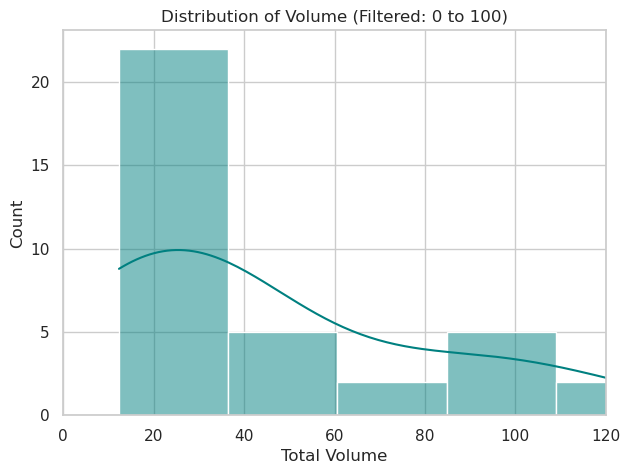

In [14]:
# 1. Generate summary statistics for the 0-100 subset
print("\n=== Summary Statistics (Volume 0 to 100) ===")
print(df_subset.describe().round(4))

# 2. Plot the height vs volume for this specific subset
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(7, 5))

sns.histplot(data=df_subset, x="TotalVolume", kde=True, color="teal", bins=8)

plt.title("Distribution of Volume (Filtered: 0 to 100)")
plt.xlabel("Total Volume")
plt.ylabel("Count")
plt.xlim(0, 120)

plt.show()

In [15]:
# A subset for rows with TotalVolume greater than ...
vol_threshold = 30

df_above_xx = df[df["TotalVolume"] > vol_threshold].copy()

# Display how many rows match the criteria
print(f"Subset created with {len(df_above_xx)} rows out of {len(df)} total rows. \n")
print(df_above_xx)

Subset created with 19 rows out of 2225 total rows. 

      RowNumber  TotalVolume  TreeHeight  DBHqsm_cm
92           95    45.221295     32.3100      28.30
123         126    91.147252     23.4550      43.22
140         143    93.249082     33.2850      69.56
152         155    96.043228     25.9188      69.38
172         175    41.893224     30.2050      23.62
269         272    56.750022     22.9267      53.76
359         362    35.624890     21.6900      35.82
505         508    48.838654     30.8240      19.86
549         552   205.653272     29.4500      63.84
668         671   193.622570     29.5600      54.18
701         704    35.263199     26.2560      43.58
713         716    97.081618     26.5367      70.02
755         758   110.551172     35.5833      53.26
808         811    77.222361     32.4850      26.54
839         842   108.839647     32.4533      65.96
841         844    31.660972     25.9000      33.02
893         896    52.249652     14.5400      27.48
914       

**The End** ________